# Welcome to Colab!

In [ ]:
# Import the libraries
import numpy as np
import matplotlib.pyplot as plt
import os
from PIL import Image
from sklearn.datasets import fetch_olivetti_faces

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Download the Olivetti Faces Dataset
faces = fetch_olivetti_faces(shuffle=True, random_state=42)

# Extract facial images and their labels
X = faces.images
y = faces.target

print("Dataset downloaded successfully!")
print("Total images:", len(X))
print("Number of people:", len(np.unique(y)))
print("Image dimensions:", X.shape[1:])

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Dataset downloaded successfully!
Total images: 400
Number of people: 40
Image dimensions: (64, 64)


In [ ]:
# Select 5 images from each person
selected_images = []
selected_labels = []

for person in np.unique(y):
    person_indices = np.where(y == person)[0][:5]

    for index in person_indices:
        selected_images.append(X[index])
        selected_labels.append(y[index])

# Convert lists into NumPy arrays
X_200 = np.array(selected_images)
y_200 = np.array(selected_labels)

print("Selected images:", len(X_200))
print("Number of people:", len(np.unique(y_200)))

Selected images: 200
Number of people: 40


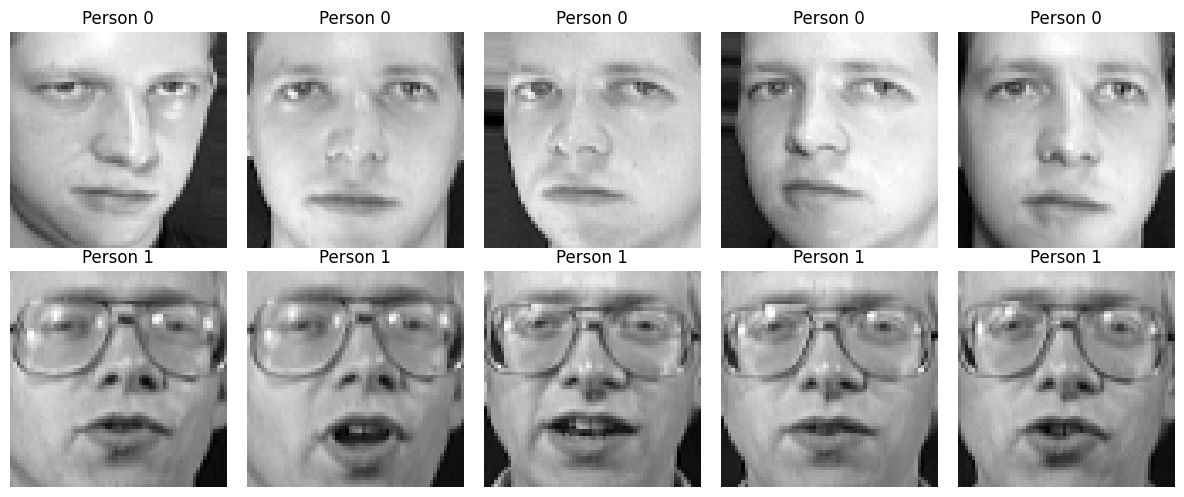

In [ ]:
# Display the first 10 facial images
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_200[i], cmap="gray")
    plt.title(f"Person {y_200[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Create a folder for our dataset
dataset_folder = "/content/CSC309_Facial_Dataset"

os.makedirs(dataset_folder, exist_ok=True)

# Save each image in its person's folder
for i in range(len(X_200)):

    person_folder = os.path.join(
        dataset_folder,
        f"Person_{y_200[i]}"
    )

    os.makedirs(person_folder, exist_ok=True)

    image = (X_200[i] * 255).astype(np.uint8)

    image = Image.fromarray(image)

    image.save(
        os.path.join(person_folder, f"image_{i}.png")
    )

print("200 facial images saved successfully!")

200 facial images saved successfully!


Colab notebooks allow you to combine **executable code** and **rich text** in a single document, along with **images**, **HTML**, **LaTeX** and more. When you create your own Colab notebooks, they are stored in your Google Drive account. You can easily share your Colab notebooks with co-workers or friends, allowing them to comment on your notebooks or even edit them. To learn more, see [Overview of Colab](/notebooks/basic_features_overview.ipynb). To create a new Colab notebook you can use the File menu above, or use the following link: [create a new Colab notebook](http://colab.research.google.com#create=true).

Colab notebooks are Jupyter notebooks that are hosted by Colab. To learn more about the Jupyter project, see [jupyter.org](https://www.jupyter.org).

## Google Colab is available in VS Code!
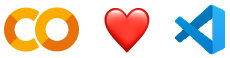

Try the new [Google Colab extension](https://marketplace.visualstudio.com/items?itemName=Google.colab) for Visual Studio Code. You can get up and running in just a few clicks:

*  In VS Code, open the ***Extensions*** view and search for 'Google Colab' to install.
*  Open the kernel selector by creating or opening any `.ipynb` notebook file in your local workspace and either running a cell or clicking the ***Select Kernel*** button in the top right.
*  Click ***Colab*** and then select your desired runtime, sign in with your Google account, and you're all set!

See more details in our [announcement blog here](https://developers.googleblog.com/google-colab-is-coming-to-vs-code).

In [9]:
# Import necessary libraries
import numpy as np
from sklearn.datasets import fetch_olivetti_faces

# Download the facial dataset
print("Downloading facial dataset...")

faces = fetch_olivetti_faces(
    shuffle=True,
    random_state=42
)

# Get images and labels
X = faces.images
y = faces.target

# Select 5 images from each person
selected_images = []
selected_labels = []

for person in np.unique(y):

    indices = np.where(y == person)[0][:5]

    for index in indices:
        selected_images.append(X[index])
        selected_labels.append(y[index])

# Convert to arrays
X_200 = np.array(selected_images)
y_200 = np.array(selected_labels)

# Display results
print("Dataset downloaded successfully!")
print("Total images:", len(X_200))
print("Number of people:", len(np.unique(y_200)))
print("Original image shape:", X_200.shape)

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Dataset downloaded successfully!
Total images: 200
Number of people: 40
Original image shape: (200, 64, 64)


In [10]:
from PIL import Image
import numpy as np

resized_images = []

for img in X_200:
    img_uint8 = (img * 255).astype(np.uint8)

    pil_image = Image.fromarray(img_uint8)

    resized = pil_image.resize((64, 64))

    resized_images.append(np.array(resized))

resized_images = np.array(resized_images)

print("Resizing completed!")
print("New shape:", resized_images.shape)

Resizing completed!
New shape: (200, 64, 64)


In [12]:
X_normalized = resized_images.astype("float32") / 255.0

print("Normalization completed!")
print("Minimum pixel value:", X_normalized.min())
print("Maximum pixel value:", X_normalized.max())

Normalization completed!
Minimum pixel value: 0.0
Maximum pixel value: 0.98039216


In [13]:
# Flatten the images
X_flattened = X_normalized.reshape(200, -1)

print("Flattening completed!")
print("New shape:", X_flattened.shape)

Flattening completed!
New shape: (200, 4096)


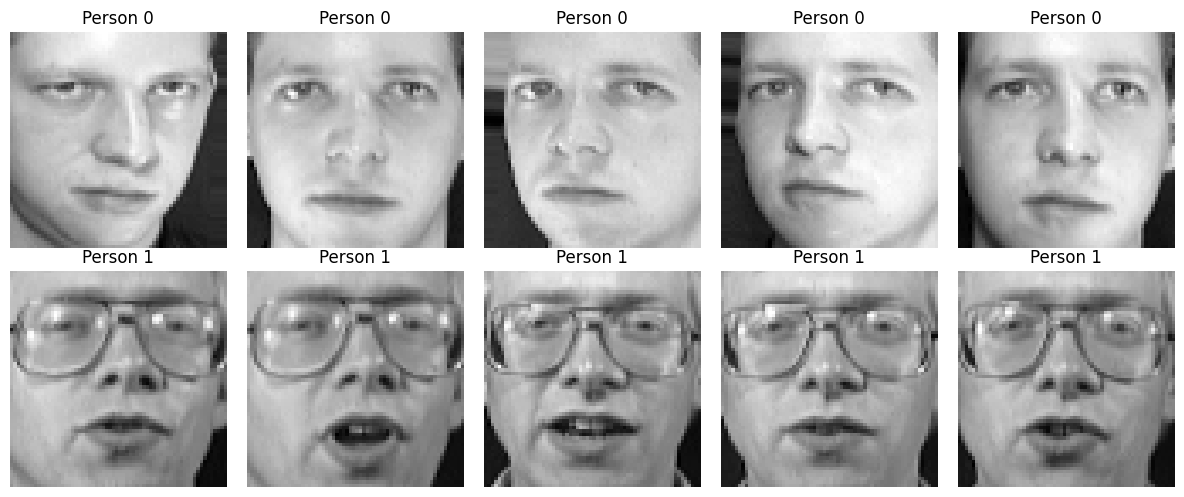

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_normalized[i].reshape(64, 64), cmap="gray")
    plt.title(f"Person {y_200[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
np.save("/content/X_preprocessed.npy", X_flattened)
np.save("/content/y_labels.npy", y_200)

print("Preprocessed images saved successfully!")

Preprocessed images saved successfully!


In [16]:
from sklearn.model_selection import train_test_split

# Divide the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X_flattened,
    y_200,
    test_size=0.2,
    random_state=42,
    stratify=y_200
)

print("Data splitting completed!")
print("Training images:", len(X_train))
print("Testing images:", len(X_test))

Data splitting completed!
Training images: 160
Testing images: 40


In [17]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Create the SVM model
svm_model = SVC(
    kernel='rbf',
    C=10,
    gamma='scale'
)

# Train the model
svm_model.fit(X_train, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [18]:
# Make predictions on testing images
y_pred = svm_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Facial Recognition Accuracy:", accuracy * 100, "%")

Facial Recognition Accuracy: 92.5 %


In [19]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         1
           2       1.00      1.00      1.00         1
           3       0.50      1.00      0.67         1
           4       1.00      1.00      1.00         1
           5       1.00      1.00      1.00         1
           6       1.00      1.00      1.00         1
           7       1.00      1.00      1.00         1
           8       1.00      1.00      1.00         1
           9       1.00      1.00      1.00         1
          10       0.50      1.00      0.67         1
          11       1.00      1.00      1.00         1
          12       0.00      0.00      0.00         1
          13       1.00      1.00      1.00         1
          14       1.00      1.00      1.00         1
          15       1.00      1.00      1.00         1
          16       0.00      0.00      0.00         1
          17       1.00    

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


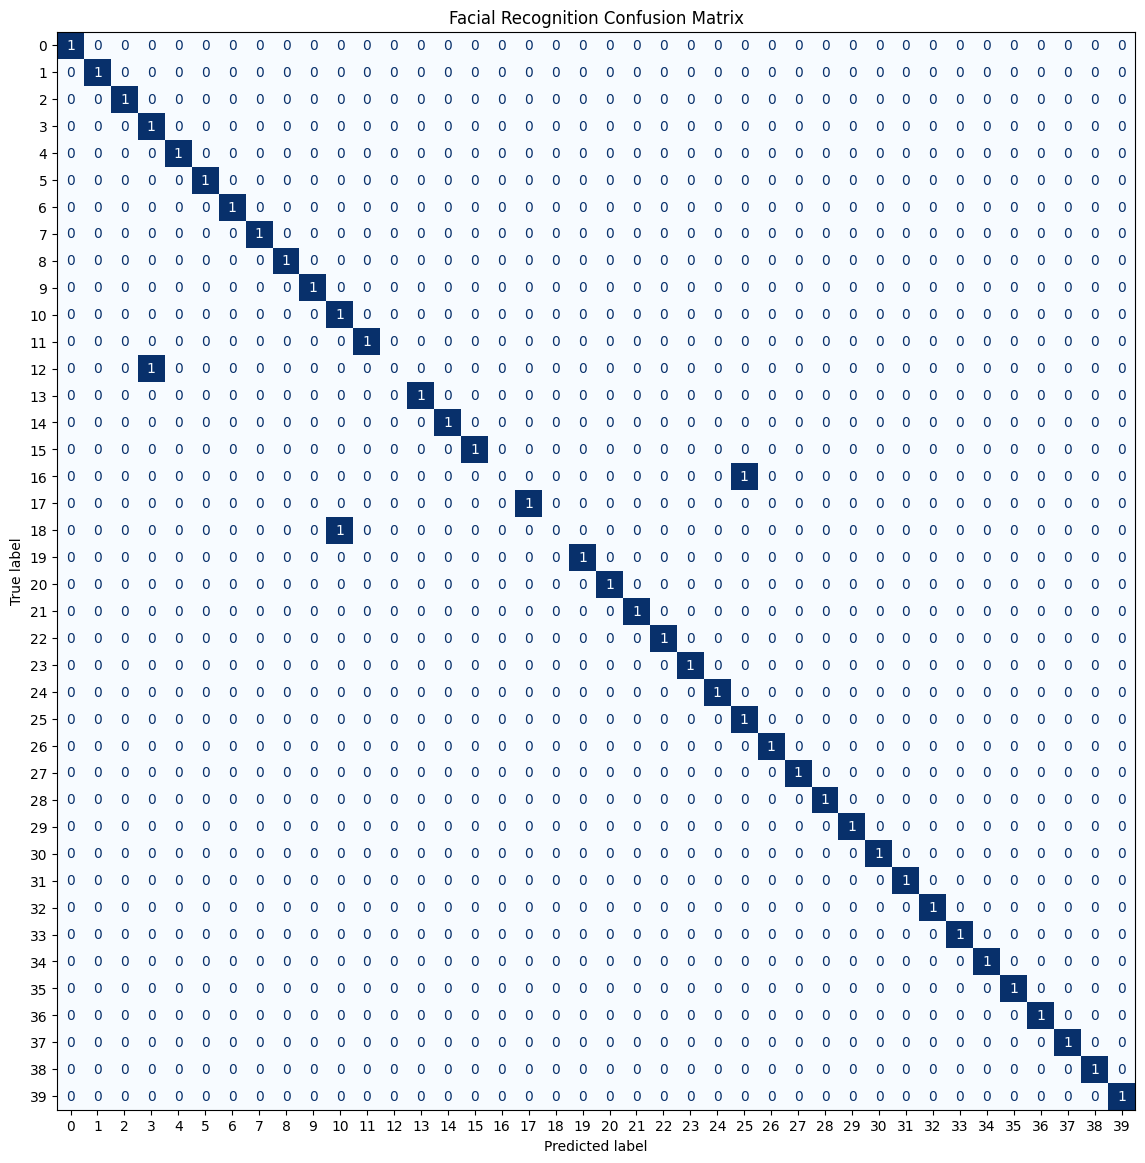

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=svm_model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=svm_model.classes_
)

fig, ax = plt.subplots(figsize=(14, 14))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Facial Recognition Confusion Matrix")
plt.show()

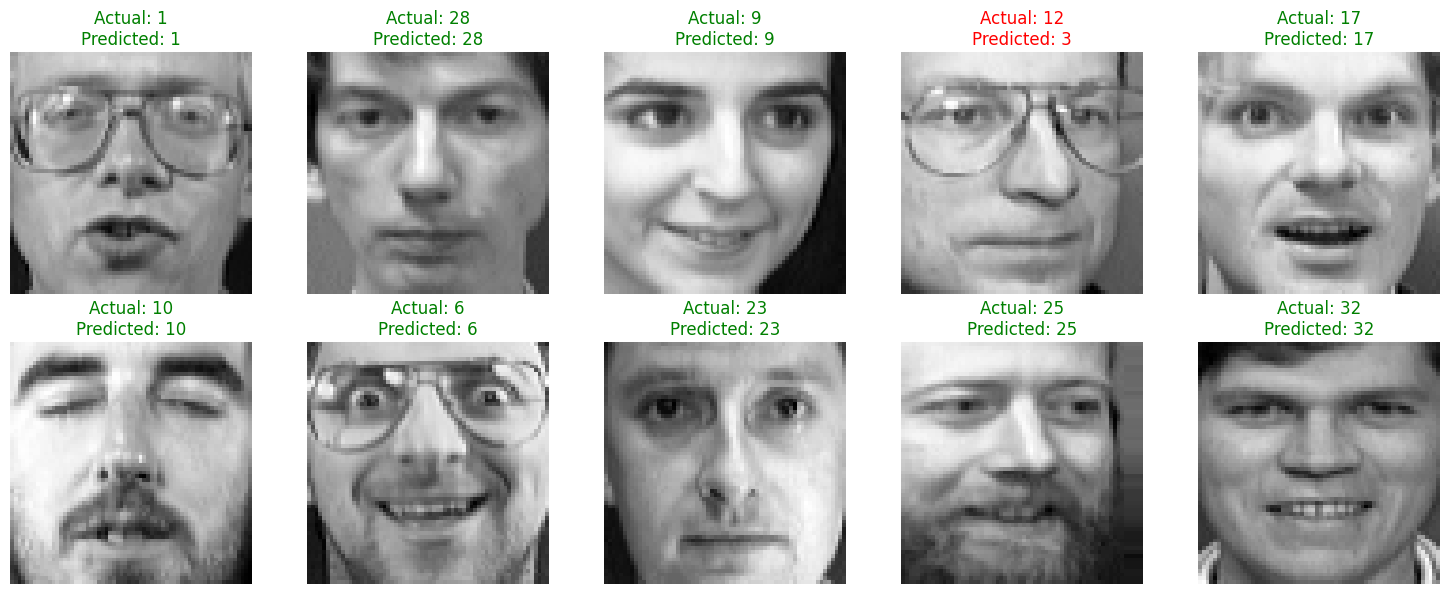

In [21]:
plt.figure(figsize=(15, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i].reshape(64, 64), cmap="gray")

    actual = y_test[i]
    predicted = y_pred[i]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color="green" if actual == predicted else "red"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [23]:
import joblib

# Save the trained SVM model
joblib.dump(
    svm_model,
    "/content/CSC309_Facial_Recognition_Model.pkl"
)

print("Facial recognition model saved successfully!")

Facial recognition model saved successfully!


In [25]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    zero_division=0
)

with open("/content/classification_report.txt", "w") as file:
    file.write(report)

print("Classification report saved successfully!")

Classification report saved successfully!


In [28]:
import os

files_to_check = [
    "/content/CSC309_Facial_Recognition_Model.pkl",
    "/content/classification_report.txt"
]

for file_path in files_to_check:
    if os.path.exists(file_path):
        print(os.path.basename(file_path), "- Saved successfully!")
    else:
        print(os.path.basename(file_path), "- Not found!")

CSC309_Facial_Recognition_Model.pkl - Saved successfully!
classification_report.txt - Saved successfully!


In [32]:
from google.colab import files

files.download("/content/CSC309_Facial_Recognition_Model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
files.download("/content/classification_report.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Colab now has AI features powered by [Gemini](https://gemini.google.com). The video below provides information on how to use these features, whether you're new to Python, or a seasoned veteran.

<center>
  <a href="https://www.youtube.com/watch?v=V7RXyqFUR98" target="_blank">
  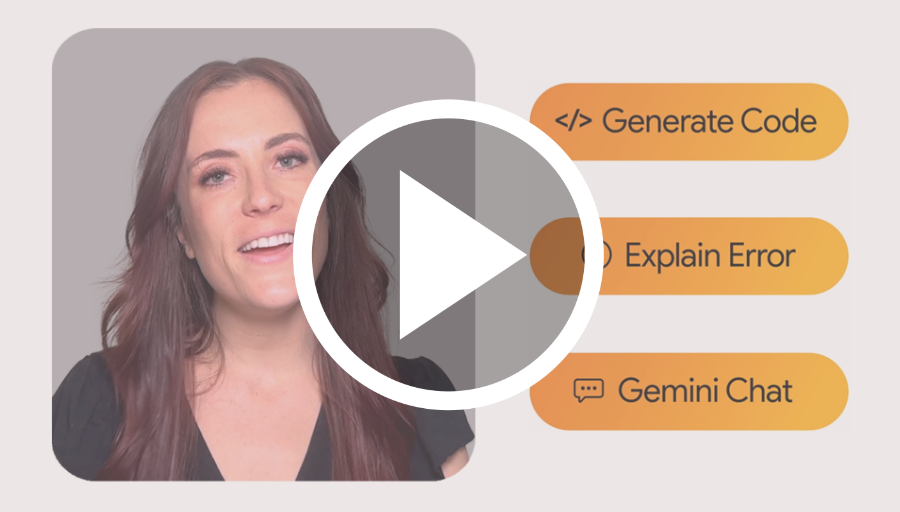
  </a>
</center>

In [33]:
requirements = """
numpy
matplotlib
scikit-learn
Pillow
joblib
"""

with open("/content/requirements.txt", "w") as file:
    file.write(requirements.strip())

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [34]:
from google.colab import files

files.download("/content/requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
readme_content = """
# CSC 309 - Facial Recognition System

## 1. Project Description
This project develops a facial recognition system using
Computer Vision and Supervised Machine Learning.

The system uses Python and Support Vector Machine (SVM)
to identify individuals from facial images.

## 2. Dataset
Dataset: Olivetti Faces Dataset

- Original images: 400
- Selected images: 200
- Number of individuals: 40
- Images selected per individual: 5
- Image dimensions: 64 x 64 pixels

Dataset source:
https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_olivetti_faces.html

## 3. Technologies Used
- Python
- Google Colab
- NumPy
- Matplotlib
- Scikit-learn
- Pillow
- Joblib

## 4. Image Preprocessing
The following preprocessing operations were performed:
- Image resizing
- Pixel normalization
- Image flattening

## 5. Machine Learning Algorithm
Support Vector Machine (SVM) with an RBF kernel
was used for facial recognition.

## 6. Model Evaluation
Training images: 160
Testing images: 40

Facial Recognition Accuracy: 92.5%

Correct predictions: 37
Incorrect predictions: 3

## 7. Evaluation Techniques
- Classification Report
- Confusion Matrix
- Actual versus Predicted Images

## 8. Project Files
- facial_recognition.ipynb
- requirements.txt
- CSC309_Facial_Recognition_Model.pkl
- classification_report.txt

## 9. How to Run the Project

Install the required libraries using:

pip install -r requirements.txt

Open the notebook in Google Colab and run
the code cells from beginning to end.

## 10. Conclusion
The project successfully demonstrates how
Computer Vision and supervised machine learning
can be used to develop a facial recognition system.

The model achieved 92.5% accuracy on the test dataset.

This project is intended for educational purposes.
"""

with open("/content/README.md", "w") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [36]:
from google.colab import files

files.download("/content/README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
print("X_200 exists:", 'X_200' in globals())
print("y_200 exists:", 'y_200' in globals())

X_200 exists: True
y_200 exists: True


In [39]:
import os
import numpy as np
from PIL import Image

dataset_folder = "/content/CSC309_Facial_Dataset"

os.makedirs(dataset_folder, exist_ok=True)

for i in range(len(X_200)):

    person_folder = os.path.join(
        dataset_folder,
        f"Person_{y_200[i]}"
    )

    os.makedirs(person_folder, exist_ok=True)

    image = (X_200[i] * 255).astype(np.uint8)

    Image.fromarray(image).save(
        os.path.join(person_folder, f"image_{i}.png")
    )

print("200 facial images saved successfully!")

200 facial images saved successfully!


In [40]:
import shutil

shutil.make_archive(
    "/content/CSC309_Facial_Dataset",
    "zip",
    "/content/CSC309_Facial_Dataset"
)

print("Dataset ZIP created successfully!")

Dataset ZIP created successfully!


In [41]:
from google.colab import files

files.download("/content/CSC309_Facial_Dataset.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
import os
import numpy as np
from PIL import Image

# Create the main dataset folder
dataset_folder = "/content/CSC309_Facial_Dataset"
os.makedirs(dataset_folder, exist_ok=True)

# Save all 200 facial images
for i in range(len(X_200)):
    person_folder = os.path.join(
        dataset_folder, f"Person_{y_200[i]}"
    )
    os.makedirs(person_folder, exist_ok=True)

    image = (X_200[i] * 255).astype(np.uint8)

    Image.fromarray(image).save(
        os.path.join(person_folder, f"image_{i}.png")
    )

print("200 facial images saved successfully!")
print("Total images:", len(os.listdir(dataset_folder)))

200 facial images saved successfully!
Total images: 40


In [43]:
import shutil

shutil.make_archive(
    "/content/CSC309_Facial_Dataset",
    "zip",
    "/content/CSC309_Facial_Dataset"
)

print("Dataset ZIP created successfully!")

Dataset ZIP created successfully!


In [44]:
from google.colab import files

files.download("/content/CSC309_Facial_Dataset.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<div class="markdown-google-sans">

## Data science
</div>

With Colab you can harness the full power of popular Python libraries to analyze and visualize data. The code cell below uses **numpy** to generate some random data, and uses **matplotlib** to visualize it. To edit the code, just click the cell and start editing.

You can import your own data into Colab notebooks from your Google Drive account, including from spreadsheets, as well as from Github and many other sources. To learn more about importing data, and how Colab can be used for data science, see the links below under [Working with Data](#working-with-data).

Colab notebooks execute code on Google's cloud servers, meaning you can leverage the power of Google hardware, including [GPUs and TPUs](#using-accelerated-hardware), regardless of the power of your machine. All you need is a browser.

For example, if you find yourself waiting for **pandas** code to finish running and want to go faster, you can switch to a GPU Runtime and use libraries like [RAPIDS cuDF](https://rapids.ai/cudf-pandas) that provide zero-code-change acceleration.

To learn more about accelerating pandas on Colab, see the [10 minute guide](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_colab_demo.ipynb) or
 [US stock market data analysis demo](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_stocks_demo.ipynb).

<div class="markdown-google-sans">

## Machine learning
</div>

With Colab you can import an image dataset, train an image classifier on it, and evaluate the model, all in just [a few lines of code](https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/quickstart/beginner.ipynb).

Colab is used extensively in the machine learning community with applications including:
- Getting started with TensorFlow
- Developing and training neural networks
- Experimenting with TPUs
- Disseminating AI research
- Creating tutorials

To see sample Colab notebooks that demonstrate machine learning applications, see the [machine learning examples](#machine-learning-examples) below.

<div class="markdown-google-sans">

## More Resources

### Working with Notebooks in Colab

</div>

- [Overview of Colab](/notebooks/basic_features_overview.ipynb)
- [Guide to Markdown](/notebooks/markdown_guide.ipynb)
- [Importing libraries and installing dependencies](/notebooks/snippets/importing_libraries.ipynb)
- [Saving and loading notebooks in GitHub](https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/colab-github-demo.ipynb)
- [Interactive forms](/notebooks/forms.ipynb)
- [Interactive widgets](/notebooks/widgets.ipynb)

<div class="markdown-google-sans">

<a name="working-with-data"></a>
### Working with Data
</div>

- [Loading data: Drive, Sheets, and Google Cloud Storage](/notebooks/io.ipynb)
- [Charts: visualizing data](/notebooks/charts.ipynb)
- [Getting started with BigQuery](/notebooks/bigquery.ipynb)

<div class="markdown-google-sans">

### Machine Learning

<div>

These are a few of the notebooks related to Machine Learning, including Google's online Machine Learning course. See the [full course website](https://developers.google.com/machine-learning/crash-course/) for more.
- [Intro to Pandas DataFrame](https://colab.research.google.com/github/google/eng-edu/blob/main/ml/cc/exercises/pandas_dataframe_ultraquick_tutorial.ipynb)
- [Intro to RAPIDS cuDF to accelerate pandas](https://nvda.ws/rapids-cudf)
- [Getting Started with cuML's accelerator mode](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cuml_sklearn_colab_demo.ipynb)

<div class="markdown-google-sans">

<a name="using-accelerated-hardware"></a>
### Using Accelerated Hardware
</div>

- [Train a CNN to classify handwritten digits on the MNIST dataset using Flax NNX API](https://colab.research.google.com/github/google/flax/blob/main/docs_nnx/mnist_tutorial.ipynb)
- [Train a Vision Transformer (ViT) for image classification with JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_Vision_transformer.ipynb)
- [Text classification with a transformer language model using JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_transformer_text_classification.ipynb)

<div class="markdown-google-sans">

<a name="machine-learning-examples"></a>

### Featured examples

</div>

- [Train a miniGPT language model with JAX AI Stack](https://docs.jaxstack.ai/en/latest/JAX_for_LLM_pretraining.html)
- [LoRA/QLoRA finetuning for LLM using Tunix](https://github.com/google/tunix/blob/main/examples/qlora_gemma.ipynb)
- [Parameter-efficient fine-tuning of Gemma with LoRA and QLoRA](https://keras.io/examples/keras_recipes/parameter_efficient_finetuning_of_gemma_with_lora_and_qlora/)
- [Loading Hugging Face Transformers Checkpoints](https://keras.io/keras_hub/guides/hugging_face_keras_integration/)
- [8-bit Integer Quantization in Keras](https://keras.io/guides/int8_quantization_in_keras/)
- [Float8 training and inference with a simple Transformer model](https://keras.io/examples/keras_recipes/float8_training_and_inference_with_transformer/)
- [Pretraining a Transformer from scratch with KerasHub](https://keras.io/keras_hub/guides/transformer_pretraining/)
- [Simple MNIST convnet](https://keras.io/examples/vision/mnist_convnet/)
- [Image classification from scratch using Keras 3](https://keras.io/examples/vision/image_classification_from_scratch/)
- [Image Classification with KerasHub](https://keras.io/keras_hub/guides/classification_with_keras_hub/)
